In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from catboost import CatBoostClassifier

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)

print("Imports effectués avec succès.")

Imports effectués avec succès.


## 2. Chargement des données

Chargement et vérification du split temporel.

In [3]:
X_train = pd.read_csv("../data/weatherAUS_X_train.csv")
X_test = pd.read_csv("../data/weatherAUS_X_test.csv")
y_train = pd.read_csv("../data/weatherAUS_y_train.csv").squeeze()
y_test = pd.read_csv("../data/weatherAUS_y_test.csv").squeeze()

print("Train :", X_train.shape, y_train.shape)
print("Test  :", X_test.shape, y_test.shape)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print("\nValeurs manquantes train :", X_train.isna().sum().sum())
print("Valeurs manquantes test  :", X_test.isna().sum().sum())

print("\nRépartition cible train :")
print(y_train.value_counts())

print("\nRépartition cible test :")
print(y_test.value_counts())

Train : (113506, 23) (113506,)
Test  : (25314, 23) (25314,)
X_train : (113506, 23)
X_test  : (25314, 23)
y_train : (113506,)
y_test  : (25314,)

Valeurs manquantes train : 0
Valeurs manquantes test  : 0

Répartition cible train :
RainTomorrow
0    88583
1    24923
Name: count, dtype: int64

Répartition cible test :
RainTomorrow
0    19569
1     5745
Name: count, dtype: int64


## 3. Vérification des variables

Contrôle des variables utilisées par CatBoost.

In [4]:
print("Nombre de variables :", X_train.shape[1])

print("\nVariables :")
print(X_train.columns.tolist())

print("\nTypes :")
print(X_train.dtypes)

print("\nTypes non numériques :")
print(X_train.select_dtypes(exclude=np.number).columns.tolist())

Nombre de variables : 23

Variables :
['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'Date_sin', 'Date_cos', 'WindGustDir_sin', 'WindGustDir_cos', 'WindDir9am_sin', 'WindDir9am_cos', 'WindDir3pm_sin', 'WindDir3pm_cos']

Types :
MinTemp            float64
MaxTemp            float64
Rainfall           float64
Evaporation        float64
Sunshine           float64
WindGustSpeed      float64
WindSpeed9am       float64
WindSpeed3pm       float64
Humidity3pm        float64
Pressure9am        float64
Pressure3pm        float64
Cloud9am           float64
Cloud3pm           float64
Temp9am            float64
Temp3pm            float64
Date_sin           float64
Date_cos           float64
WindGustDir_sin    float64
WindGustDir_cos    float64
WindDir9am_sin     float64
WindDir9am_cos     float64
WindDir3pm_sin     float64
WindDir3pm_cos     floa

## 4. Modèle CatBoost de référence

Entraînement du modèle de référence sans pondération.

In [5]:
model_cb_base = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.1,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=0
)

model_cb_base.fit(X_train, y_train)

print("Entraînement terminé.")

Entraînement terminé.


## 5. Évaluation du modèle de référence

Comparaison des performances train et test.

In [6]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score,
    average_precision_score
)

y_pred_train_base = model_cb_base.predict(X_train).astype(int).ravel()
y_proba_train_base = model_cb_base.predict_proba(X_train)[:, 1]

y_pred_test_base = model_cb_base.predict(X_test).astype(int).ravel()
y_proba_test_base = model_cb_base.predict_proba(X_test)[:, 1]


def evaluate_model(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1-macro": f1_score(y_true, y_pred, average="macro"),
        "F1 (Yes)": f1_score(y_true, y_pred, pos_label=1),
        "Recall (Yes)": recall_score(y_true, y_pred, pos_label=1),
        "Precision (Yes)": precision_score(y_true, y_pred, pos_label=1),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba)
    }


scores_train_base = evaluate_model(
    y_train, y_pred_train_base, y_proba_train_base
)

scores_test_base = evaluate_model(
    y_test, y_pred_test_base, y_proba_test_base
)

results_base = pd.DataFrame(
    [scores_train_base, scores_test_base],
    index=["Train", "Test"]
)

print(results_base.round(4))

       Accuracy  F1-macro  F1 (Yes)  Recall (Yes)  Precision (Yes)  ROC-AUC  \
Train    0.8825    0.8096    0.6917        0.6002           0.8161   0.9211   
Test     0.8516    0.7666    0.6258        0.5467           0.7315   0.8800   

       PR-AUC  
Train  0.8097  
Test   0.7245  


## 6. Matrices de confusion

Visualisation des erreurs sur train et test.

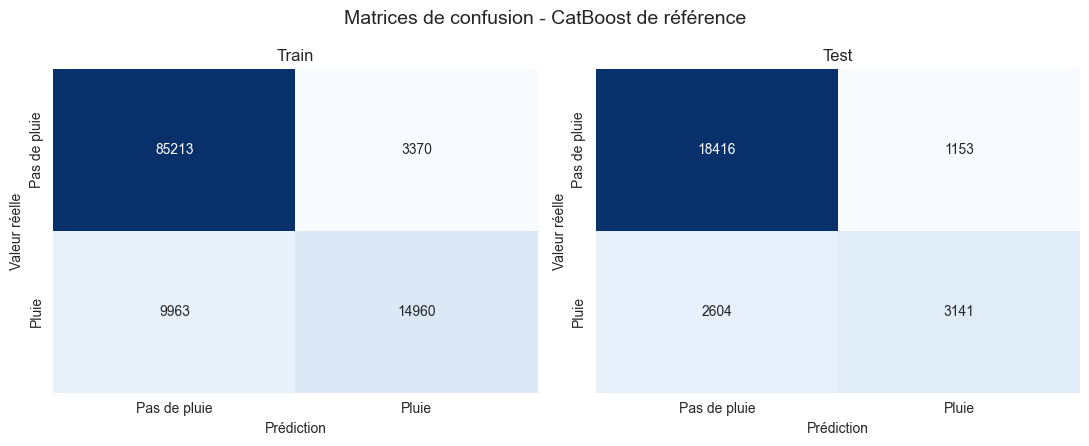

Test :
Vrais négatifs  : 18416
Faux positifs   : 1153
Faux négatifs   : 2604
Vrais positifs  : 3141


In [7]:
from sklearn.metrics import confusion_matrix

cm_train = confusion_matrix(y_train, y_pred_train_base)
cm_test = confusion_matrix(y_test, y_pred_test_base)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0]
)
axes[0].set_title("Train")
axes[0].set_xlabel("Prédiction")
axes[0].set_ylabel("Valeur réelle")
axes[0].set_xticklabels(["Pas de pluie", "Pluie"])
axes[0].set_yticklabels(["Pas de pluie", "Pluie"])

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[1]
)
axes[1].set_title("Test")
axes[1].set_xlabel("Prédiction")
axes[1].set_ylabel("Valeur réelle")
axes[1].set_xticklabels(["Pas de pluie", "Pluie"])
axes[1].set_yticklabels(["Pas de pluie", "Pluie"])

fig.suptitle(
    "Matrices de confusion - CatBoost de référence",
    fontsize=14
)

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_test.ravel()

print("Test :")
print(f"Vrais négatifs  : {tn}")
print(f"Faux positifs   : {fp}")
print(f"Faux négatifs   : {fn}")
print(f"Vrais positifs  : {tp}")

## 7. Courbes ROC et Precision-Recall

Évaluation du pouvoir discriminant du modèle.

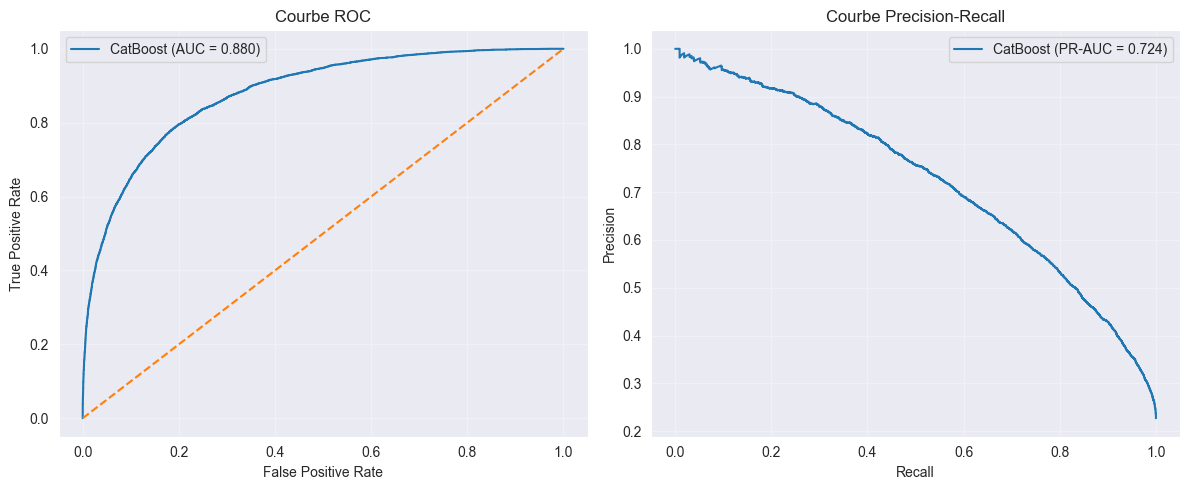

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_proba_test_base)
precision, recall, _ = precision_recall_curve(y_test, y_proba_test_base)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    fpr,
    tpr,
    label=f"CatBoost (AUC = {roc_auc_score(y_test, y_proba_test_base):.3f})"
)
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Courbe ROC")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    recall,
    precision,
    label=f"CatBoost (PR-AUC = {average_precision_score(y_test, y_proba_test_base):.3f})"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Courbe Precision-Recall")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Validation temporelle

Création d'un jeu de validation chronologique.

In [9]:
split_idx = int(len(X_train) * 0.8)

X_train_sub = X_train.iloc[:split_idx].copy()
y_train_sub = y_train.iloc[:split_idx].copy()

X_val = X_train.iloc[split_idx:].copy()
y_val = y_train.iloc[split_idx:].copy()

print("Sous-ensemble entraînement :", X_train_sub.shape, y_train_sub.shape)
print("Validation temporelle      :", X_val.shape, y_val.shape)

print("\nRépartition cible entraînement :")
print(y_train_sub.value_counts(normalize=True).round(4))

print("\nRépartition cible validation :")
print(y_val.value_counts(normalize=True).round(4))

Sous-ensemble entraînement : (90804, 23) (90804,)
Validation temporelle      : (22702, 23) (22702,)

Répartition cible entraînement :
RainTomorrow
0    0.7752
1    0.2248
Name: proportion, dtype: float64

Répartition cible validation :
RainTomorrow
0    0.8013
1    0.1987
Name: proportion, dtype: float64


## 9. CatBoost de validation

Entraînement avant optimisation du seuil.

In [10]:
model_cb_val = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.1,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=0
)

model_cb_val.fit(X_train_sub, y_train_sub)

y_proba_val = model_cb_val.predict_proba(X_val)[:, 1]
y_pred_val_05 = (y_proba_val >= 0.5).astype(int)

scores_val_05 = evaluate_model(
    y_val,
    y_pred_val_05,
    y_proba_val
)

print(pd.Series(scores_val_05).round(4))

Accuracy           0.8675
F1-macro           0.7720
F1 (Yes)           0.6245
Recall (Yes)       0.5544
Precision (Yes)    0.7148
ROC-AUC            0.9018
PR-AUC             0.7311
dtype: float64


## 10. Analyse du seuil de décision

Évolution des performances selon le seuil.

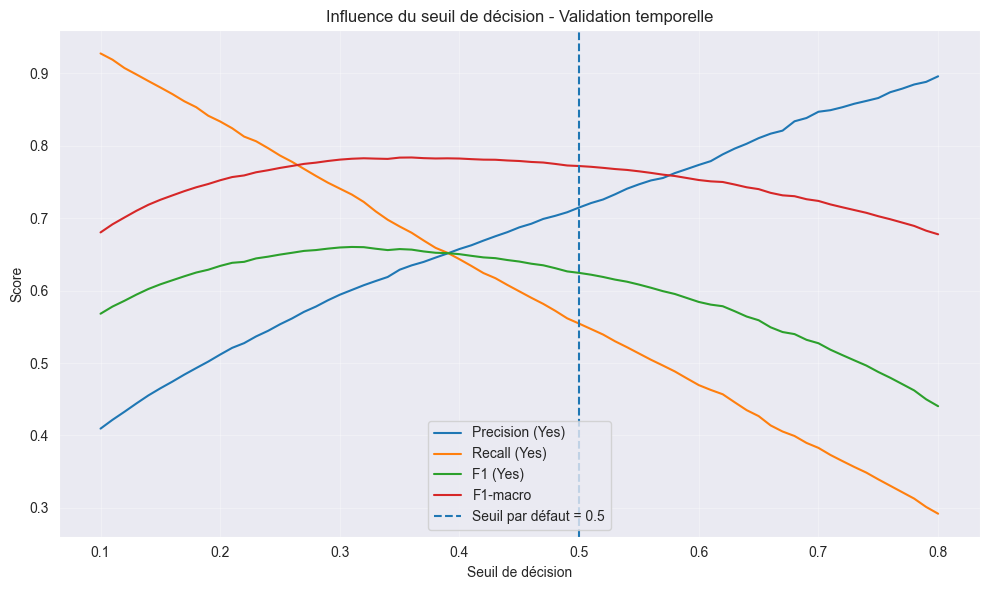

In [11]:
thresholds = np.arange(0.10, 0.81, 0.01)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba_val >= threshold).astype(int)

    threshold_results.append({
        "Seuil": threshold,
        "Precision": precision_score(y_val, y_pred_threshold, zero_division=0),
        "Recall": recall_score(y_val, y_pred_threshold),
        "F1 Yes": f1_score(y_val, y_pred_threshold),
        "F1 macro": f1_score(y_val, y_pred_threshold, average="macro")
    })

threshold_df = pd.DataFrame(threshold_results)

plt.figure(figsize=(10, 6))

plt.plot(threshold_df["Seuil"], threshold_df["Precision"], label="Precision (Yes)")
plt.plot(threshold_df["Seuil"], threshold_df["Recall"], label="Recall (Yes)")
plt.plot(threshold_df["Seuil"], threshold_df["F1 Yes"], label="F1 (Yes)")
plt.plot(threshold_df["Seuil"], threshold_df["F1 macro"], label="F1-macro")

plt.axvline(0.5, linestyle="--", label="Seuil par défaut = 0.5")

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Influence du seuil de décision - Validation temporelle")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Sélection du seuil optimal

Comparaison de plusieurs points de fonctionnement.

In [12]:
best_f1_yes_idx = threshold_df["F1 Yes"].idxmax()
best_f1_macro_idx = threshold_df["F1 macro"].idxmax()

threshold_f1_yes = threshold_df.loc[best_f1_yes_idx, "Seuil"]
threshold_f1_macro = threshold_df.loc[best_f1_macro_idx, "Seuil"]

eligible_recall = threshold_df[threshold_df["Recall"] >= 0.75]

if len(eligible_recall) > 0:
    best_recall_idx = eligible_recall["Precision"].idxmax()
    threshold_recall_75 = threshold_df.loc[best_recall_idx, "Seuil"]
else:
    threshold_recall_75 = np.nan

comparison_thresholds = threshold_df[
    threshold_df["Seuil"].isin([
        0.5,
        threshold_f1_yes,
        threshold_f1_macro,
        threshold_recall_75
    ])
].copy()

print("Seuil par défaut :", 0.50)
print("Seuil max F1 Yes :", round(threshold_f1_yes, 2))
print("Seuil max F1-macro :", round(threshold_f1_macro, 2))
print("Seuil pour Recall >= 0.75 :", round(threshold_recall_75, 2))

print("\nComparaison sur la validation temporelle :")
print(comparison_thresholds.round(4).to_string(index=False))

Seuil par défaut : 0.5
Seuil max F1 Yes : 0.31
Seuil max F1-macro : 0.36
Seuil pour Recall >= 0.75 : 0.28

Comparaison sur la validation temporelle :
 Seuil  Precision  Recall  F1 Yes  F1 macro
  0.28     0.5780  0.7584  0.6560    0.7767
  0.31     0.6009  0.7327  0.6603    0.7821
  0.36     0.6349  0.6799  0.6566    0.7838


## 12. Évaluation avec seuil optimisé

Application du seuil choisi au test.

In [13]:
threshold_opt = threshold_f1_yes

y_pred_test_opt = (y_proba_test_base >= threshold_opt).astype(int)

scores_test_opt = {
    "Accuracy": accuracy_score(y_test, y_pred_test_opt),
    "F1-macro": f1_score(y_test, y_pred_test_opt, average="macro"),
    "F1 (Yes)": f1_score(y_test, y_pred_test_opt),
    "Recall (Yes)": recall_score(y_test, y_pred_test_opt),
    "Precision (Yes)": precision_score(y_test, y_pred_test_opt),
    "ROC-AUC": roc_auc_score(y_test, y_proba_test_base),
    "PR-AUC": average_precision_score(y_test, y_proba_test_base)
}

print(f"Seuil retenu : {threshold_opt:.2f}\n")
print(pd.Series(scores_test_opt).round(4))

Seuil retenu : 0.31

Accuracy           0.8312
F1-macro           0.7726
F1 (Yes)           0.6571
Recall (Yes)       0.7126
Precision (Yes)    0.6096
ROC-AUC            0.8800
PR-AUC             0.7245
dtype: float64


## 13. Impact du seuil sur les erreurs

Comparaison des matrices de confusion.

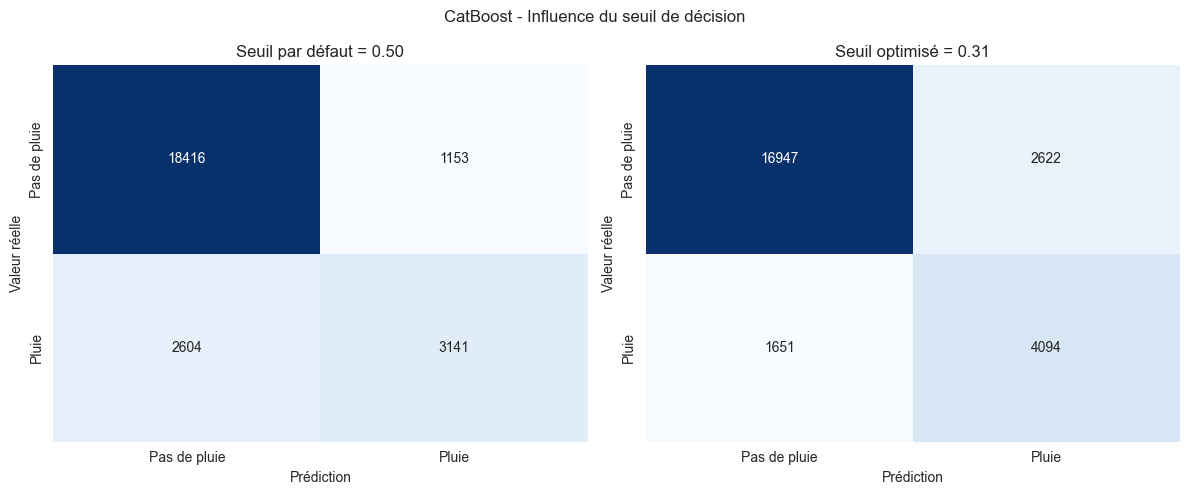

Seuil 0.50
Faux négatifs : 2604
Vrais positifs : 3141

Seuil 0.31
Faux négatifs : 1651
Vrais positifs : 4094

Jours de pluie supplémentaires détectés : 953
Faux négatifs évités : 953


In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_default = confusion_matrix(y_test, y_pred_test_base)
cm_opt = confusion_matrix(y_test, y_pred_test_opt)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_default,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0]
)
axes[0].set_title("Seuil par défaut = 0.50")
axes[0].set_xlabel("Prédiction")
axes[0].set_ylabel("Valeur réelle")
axes[0].set_xticklabels(["Pas de pluie", "Pluie"])
axes[0].set_yticklabels(["Pas de pluie", "Pluie"])

sns.heatmap(
    cm_opt,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[1]
)
axes[1].set_title(f"Seuil optimisé = {threshold_opt:.2f}")
axes[1].set_xlabel("Prédiction")
axes[1].set_ylabel("Valeur réelle")
axes[1].set_xticklabels(["Pas de pluie", "Pluie"])
axes[1].set_yticklabels(["Pas de pluie", "Pluie"])

plt.suptitle("CatBoost - Influence du seuil de décision")
plt.tight_layout()
plt.show()

tn_base, fp_base, fn_base, tp_base = cm_default.ravel()
tn_opt, fp_opt, fn_opt, tp_opt = cm_opt.ravel()

print("Seuil 0.50")
print(f"Faux négatifs : {fn_base}")
print(f"Vrais positifs : {tp_base}")

print(f"\nSeuil {threshold_opt:.2f}")
print(f"Faux négatifs : {fn_opt}")
print(f"Vrais positifs : {tp_opt}")

print(f"\nJours de pluie supplémentaires détectés : {tp_opt - tp_base}")
print(f"Faux négatifs évités : {fn_base - fn_opt}")

## 14. Optimisation des hyperparamètres

Recherche temporelle des meilleurs paramètres.

In [15]:
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from catboost import CatBoostClassifier

param_grid = {
    "depth": [6, 8],
    "learning_rate": [0.05, 0.1],
    "iterations": [300, 500],
    "l2_leaf_reg": [3, 5]
}

tscv = TimeSeriesSplit(n_splits=3)

grid_results = []

for params in ParameterGrid(param_grid):

    fold_scores = []

    for train_idx, val_idx in tscv.split(X_train):

        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        model = CatBoostClassifier(
            **params,
            random_seed=42,
            verbose=0
        )

        model.fit(X_fold_train, y_fold_train)

        y_proba_fold = model.predict_proba(X_fold_val)[:, 1]

        fold_scores.append(
            roc_auc_score(y_fold_val, y_proba_fold)
        )

    grid_results.append({
        **params,
        "ROC-AUC moyen": np.mean(fold_scores),
        "ROC-AUC std": np.std(fold_scores)
    })

grid_results_df = pd.DataFrame(grid_results)

grid_results_df = grid_results_df.sort_values(
    "ROC-AUC moyen",
    ascending=False
).reset_index(drop=True)

print(grid_results_df.head(10).round(4))

best_params = grid_results_df.iloc[0]

print("\nMeilleurs paramètres :")
print(best_params)

   depth  iterations  l2_leaf_reg  learning_rate  ROC-AUC moyen  ROC-AUC std
0      8         500            3           0.05         0.8820       0.0139
1      8         500            5           0.05         0.8818       0.0136
2      6         500            5           0.05         0.8817       0.0128
3      6         500            3           0.05         0.8814       0.0137
4      8         300            5           0.05         0.8814       0.0142
5      6         300            3           0.10         0.8813       0.0132
6      8         300            3           0.05         0.8810       0.0147
7      6         500            3           0.10         0.8806       0.0124
8      6         300            5           0.05         0.8803       0.0138
9      6         300            5           0.10         0.8803       0.0143

Meilleurs paramètres :
depth              8.000000
iterations       500.000000
l2_leaf_reg        3.000000
learning_rate      0.050000
ROC-AUC moyen    

## 15. Entraînement du modèle optimisé

Entraînement avec les meilleurs hyperparamètres.

In [16]:
model_cb_opt = CatBoostClassifier(
    depth=8,
    iterations=500,
    l2_leaf_reg=3,
    learning_rate=0.05,
    random_seed=42,
    verbose=0
)

model_cb_opt.fit(X_train, y_train)

y_pred_train_opt = model_cb_opt.predict(X_train).astype(int).ravel()
y_proba_train_opt = model_cb_opt.predict_proba(X_train)[:, 1]

y_pred_test_opt = model_cb_opt.predict(X_test).astype(int).ravel()
y_proba_test_opt = model_cb_opt.predict_proba(X_test)[:, 1]

scores_train_opt = evaluate_model(
    y_train,
    y_pred_train_opt,
    y_proba_train_opt
)

scores_test_opt = evaluate_model(
    y_test,
    y_pred_test_opt,
    y_proba_test_opt
)

results_opt = pd.DataFrame(
    [scores_train_opt, scores_test_opt],
    index=["Train", "Test"]
)

print(results_opt.round(4))

       Accuracy  F1-macro  F1 (Yes)  Recall (Yes)  Precision (Yes)  ROC-AUC  \
Train    0.8863    0.8154    0.7009        0.6065           0.8301   0.9259   
Test     0.8517    0.7659    0.6243        0.5431           0.7341   0.8811   

       PR-AUC  
Train  0.8210  
Test   0.7249  


## 16. Optimisation du seuil de décision

Recherche du seuil sur validation temporelle.

In [17]:
model_cb_opt_val = CatBoostClassifier(
    depth=8,
    iterations=500,
    l2_leaf_reg=3,
    learning_rate=0.05,
    random_seed=42,
    verbose=0
)

model_cb_opt_val.fit(X_train_sub, y_train_sub)

y_proba_val_opt = model_cb_opt_val.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.10, 0.81, 0.01)

threshold_results_opt = []

for threshold in thresholds:
    y_pred_val_threshold = (y_proba_val_opt >= threshold).astype(int)

    threshold_results_opt.append({
        "Seuil": threshold,
        "Precision": precision_score(y_val, y_pred_val_threshold),
        "Recall": recall_score(y_val, y_pred_val_threshold),
        "F1 Yes": f1_score(y_val, y_pred_val_threshold),
        "F1 macro": f1_score(y_val, y_pred_val_threshold, average="macro")
    })

threshold_results_opt = pd.DataFrame(threshold_results_opt)

best_idx = threshold_results_opt["F1 Yes"].idxmax()
threshold_opt_final = threshold_results_opt.loc[best_idx, "Seuil"]

print(f"Seuil optimal F1 Yes : {threshold_opt_final:.2f}")
print()
print(threshold_results_opt.loc[best_idx].round(4))

Seuil optimal F1 Yes : 0.34

Seuil        0.3400
Precision    0.6290
Recall       0.6965
F1 Yes       0.6611
F1 macro     0.7857
Name: 24, dtype: float64


## 17. Évaluation au seuil optimisé

Application du seuil au test final.

In [18]:
y_pred_test_final = (
    y_proba_test_opt >= threshold_opt_final
).astype(int)

scores_test_final = evaluate_model(
    y_test,
    y_pred_test_final,
    y_proba_test_opt
)

print(f"Seuil retenu : {threshold_opt_final:.2f}\n")
print(pd.Series(scores_test_final).round(4))

Seuil retenu : 0.34

Accuracy           0.8390
F1-macro           0.7766
F1 (Yes)           0.6585
Recall (Yes)       0.6841
Precision (Yes)    0.6348
ROC-AUC            0.8811
PR-AUC             0.7249
dtype: float64


### Évaluation train au seuil final

In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

y_proba_train = model_cb_opt.predict_proba(X_train)[:, 1]
y_pred_train_final = (y_proba_train >= threshold_opt_final).astype(int)

print(f"Seuil : {threshold_opt_final:.2f}")
print(f"F1-score (Yes) : {f1_score(y_train, y_pred_train_final):.4f}")
print(f"Recall (Yes) : {recall_score(y_train, y_pred_train_final):.4f}")
print(f"Precision (Yes) : {precision_score(y_train, y_pred_train_final):.4f}")
print(f"AUC-ROC : {roc_auc_score(y_train, y_proba_train):.4f}")
print(f"PR-AUC : {average_precision_score(y_train, y_proba_train):.4f}")

Seuil : 0.34
F1-score (Yes) : 0.7267
Recall (Yes) : 0.7508
Precision (Yes) : 0.7041
AUC-ROC : 0.9259
PR-AUC : 0.8210


## 18. Pondération des classes

Rééquilibrage du coût des erreurs.

In [20]:
neg = (y_train_sub == 0).sum()
pos = (y_train_sub == 1).sum()

class_weight_ratio = neg / pos

print(f"Classe 0 : {neg}")
print(f"Classe 1 : {pos}")
print(f"Poids calculé pour la pluie : {class_weight_ratio:.3f}")

model_cb_weighted_val = CatBoostClassifier(
    depth=8,
    iterations=500,
    l2_leaf_reg=3,
    learning_rate=0.05,
    class_weights=[1, class_weight_ratio],
    random_seed=42,
    verbose=0
)

model_cb_weighted_val.fit(X_train_sub, y_train_sub)

y_proba_val_weighted = model_cb_weighted_val.predict_proba(X_val)[:, 1]

y_pred_val_weighted_05 = (
    y_proba_val_weighted >= 0.5
).astype(int)

scores_val_weighted_05 = evaluate_model(
    y_val,
    y_pred_val_weighted_05,
    y_proba_val_weighted
)

print("\nPerformances validation au seuil 0.50 :")
print(pd.Series(scores_val_weighted_05).round(4))

Classe 0 : 70392
Classe 1 : 20412
Poids calculé pour la pluie : 3.449

Performances validation au seuil 0.50 :
Accuracy           0.8346
F1-macro           0.7728
F1 (Yes)           0.6543
Recall (Yes)       0.7879
Precision (Yes)    0.5594
ROC-AUC            0.9037
PR-AUC             0.7390
dtype: float64


## 19. Seuil du modèle pondéré

Optimisation sur la validation temporelle.

In [21]:
thresholds = np.arange(0.10, 0.81, 0.01)

threshold_results_weighted = []

for threshold in thresholds:
    y_pred = (y_proba_val_weighted >= threshold).astype(int)

    threshold_results_weighted.append({
        "Seuil": threshold,
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Yes": f1_score(y_val, y_pred),
        "F1 macro": f1_score(y_val, y_pred, average="macro")
    })

threshold_results_weighted = pd.DataFrame(
    threshold_results_weighted
)

best_idx_weighted = (
    threshold_results_weighted["F1 Yes"].idxmax()
)

threshold_weighted_opt = threshold_results_weighted.loc[
    best_idx_weighted, "Seuil"
]

print(
    f"Seuil optimal F1 Yes : "
    f"{threshold_weighted_opt:.2f}"
)

print()
print(
    threshold_results_weighted
    .loc[best_idx_weighted]
    .round(4)
)

Seuil optimal F1 Yes : 0.61

Seuil        0.6100
Precision    0.6326
Recall       0.6961
F1 Yes       0.6628
F1 macro     0.7869
Name: 51, dtype: float64


## 20. Évaluation finale du modèle pondéré

Entraînement complet et évaluation finale.

In [22]:
neg_train = (y_train == 0).sum()
pos_train = (y_train == 1).sum()

class_weight_final = neg_train / pos_train

model_cb_weighted = CatBoostClassifier(
    depth=8,
    iterations=500,
    l2_leaf_reg=3,
    learning_rate=0.05,
    class_weights=[1, class_weight_final],
    random_seed=42,
    verbose=0
)

model_cb_weighted.fit(X_train, y_train)

y_proba_test_weighted = model_cb_weighted.predict_proba(X_test)[:, 1]

y_pred_test_weighted = (
    y_proba_test_weighted >= threshold_weighted_opt
).astype(int)

scores_test_weighted = evaluate_model(
    y_test,
    y_pred_test_weighted,
    y_proba_test_weighted
)

print(f"Poids classe pluie : {class_weight_final:.3f}")
print(f"Seuil retenu : {threshold_weighted_opt:.2f}\n")

print(pd.Series(scores_test_weighted).round(4))

Poids classe pluie : 3.554
Seuil retenu : 0.61

Accuracy           0.8341
F1-macro           0.7734
F1 (Yes)           0.6562
Recall (Yes)       0.6978
Precision (Yes)    0.6193
ROC-AUC            0.8808
PR-AUC             0.7241
dtype: float64


## 21. Comparaison des variantes CatBoost

Comparaison des stratégies de classification.

In [23]:
comparison_final = pd.DataFrame({
    "Baseline (seuil 0.50)": scores_test_base,
    "Optimisé (seuil 0.34)": scores_test_final,
    "Pondéré (seuil 0.61)": scores_test_weighted
}).T

print(comparison_final.round(4))

                       Accuracy  F1-macro  F1 (Yes)  Recall (Yes)  \
Baseline (seuil 0.50)    0.8516    0.7666    0.6258        0.5467   
Optimisé (seuil 0.34)    0.8390    0.7766    0.6585        0.6841   
Pondéré (seuil 0.61)     0.8341    0.7734    0.6562        0.6978   

                       Precision (Yes)  ROC-AUC  PR-AUC  
Baseline (seuil 0.50)           0.7315   0.8800  0.7245  
Optimisé (seuil 0.34)           0.6348   0.8811  0.7249  
Pondéré (seuil 0.61)            0.6193   0.8808  0.7241  


## 22. Importance des variables

Variables les plus influentes du modèle.

In [24]:
feature_importance = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": model_cb_opt.get_feature_importance()
}).sort_values("Importance", ascending=False)

print(feature_importance.head(15).round(4))

           Variable  Importance
8       Humidity3pm     16.9913
10      Pressure3pm      9.3282
4          Sunshine      9.1413
5     WindGustSpeed      7.8841
16         Date_cos      5.2675
12         Cloud3pm      4.9484
9       Pressure9am      4.6498
2          Rainfall      4.1175
15         Date_sin      3.6730
22   WindDir3pm_cos      3.6093
17  WindGustDir_sin      2.9853
1           MaxTemp      2.9283
7      WindSpeed3pm      2.6599
13          Temp9am      2.6252
0           MinTemp      2.3998


## 23. Importance globale

Visualisation des variables les plus importantes.

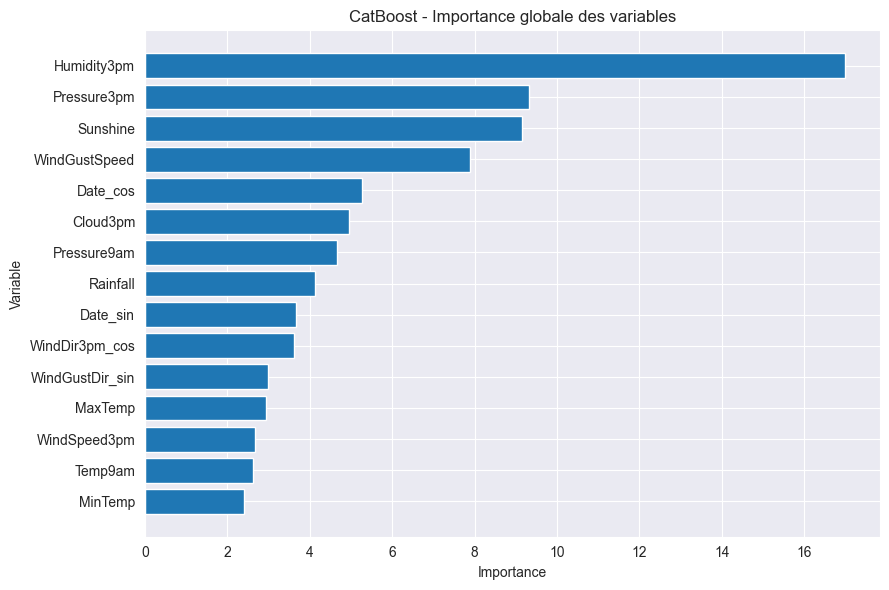

In [25]:
top_features = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Variable"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Variable")
plt.title("CatBoost - Importance globale des variables")
plt.tight_layout()
plt.show()

## 24. Importance par permutation

Mesure robuste de l'influence des variables.

In [26]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    model_cb_opt,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Variable": X_test.columns,
    "Importance": perm_importance.importances_mean,
    "Ecart_type": perm_importance.importances_std
}).sort_values("Importance", ascending=False)

print(permutation_df.head(15).round(4))

           Variable  Importance  Ecart_type
8       Humidity3pm      0.1275      0.0005
10      Pressure3pm      0.0796      0.0012
5     WindGustSpeed      0.0385      0.0009
4          Sunshine      0.0187      0.0005
9       Pressure9am      0.0100      0.0003
16         Date_cos      0.0067      0.0006
22   WindDir3pm_cos      0.0051      0.0003
12         Cloud3pm      0.0045      0.0002
2          Rainfall      0.0045      0.0006
7      WindSpeed3pm      0.0037      0.0003
13          Temp9am      0.0037      0.0002
17  WindGustDir_sin      0.0030      0.0002
1           MaxTemp      0.0030      0.0003
20   WindDir9am_cos      0.0025      0.0002
19   WindDir9am_sin      0.0023      0.0002


## 25. Importance par permutation

Visualisation de l'impact prédictif des variables.

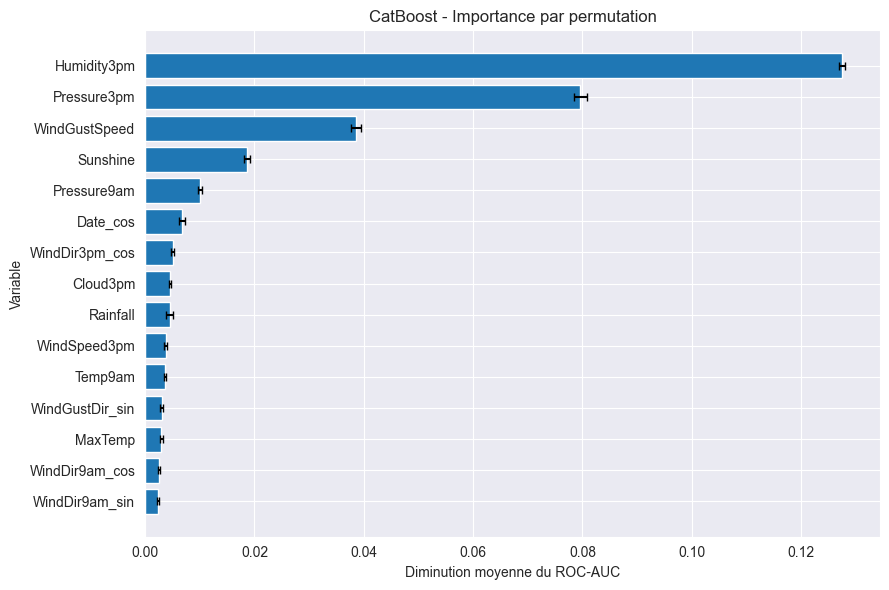

In [27]:
top_perm = permutation_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_perm["Variable"],
    top_perm["Importance"],
    xerr=top_perm["Ecart_type"],
    capsize=3
)

plt.xlabel("Diminution moyenne du ROC-AUC")
plt.ylabel("Variable")
plt.title("CatBoost - Importance par permutation")
plt.tight_layout()
plt.show()

## 26. Analyse SHAP globale

Calcul des contributions SHAP du modèle.

In [28]:
import sys
print(sys.executable)

C:\Users\arthu\PycharmProjects\juin25_alt2_mle_meteo\.venv\Scripts\python.exe


In [29]:
!{sys.executable} -m pip show shap

Name: shap
Version: 0.52.0
Summary: A unified approach to explain the output of any machine learning model.
Home-page: 
Author: 
Author-email: Scott Lundberg <slund1@cs.washington.edu>
License: MIT License
Location: C:\Users\arthu\PycharmProjects\juin25_alt2_mle_meteo\.venv\Lib\site-packages
Requires: cloudpickle, llvmlite, numba, numpy, packaging, pandas, scikit-learn, scipy, slicer, tqdm
Required-by: 


In [30]:
import shap

N_SHAP = min(5000, len(X_test))

X_shap = X_test.sample(
    n=N_SHAP,
    random_state=42
)

explainer = shap.TreeExplainer(model_cb_opt)
shap_values = explainer.shap_values(X_shap)

print("Échantillon SHAP :", X_shap.shape)
print("Valeurs SHAP :", np.asarray(shap_values).shape)

C:\Users\arthu\PycharmProjects\juin25_alt2_mle_meteo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Échantillon SHAP : (5000, 23)
Valeurs SHAP : (5000, 23)


## 27. SHAP global

Impact et direction des variables principales.

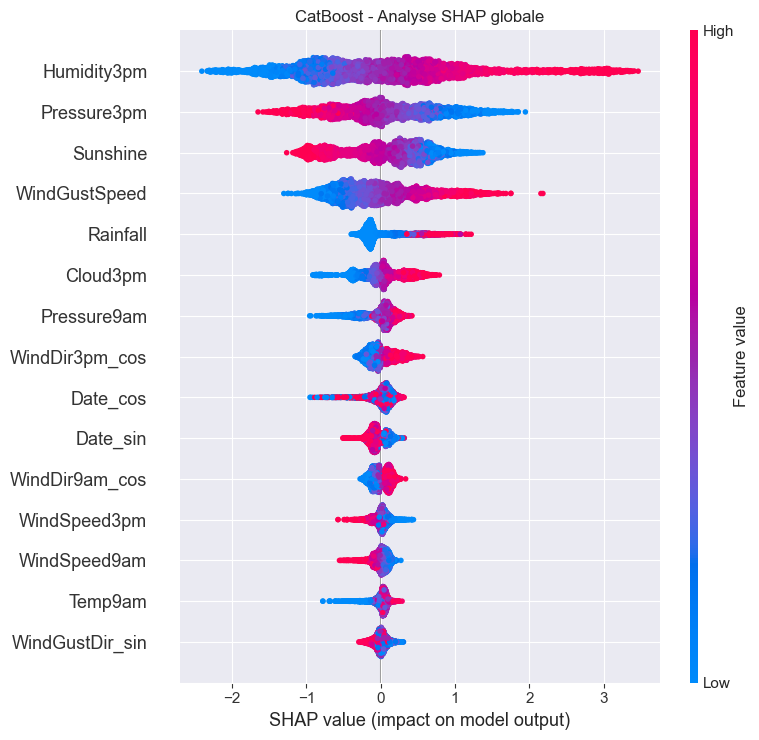

In [31]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15,
    show=False
)

plt.title("CatBoost - Analyse SHAP globale")
plt.tight_layout()
plt.show()

## 28. Dépendances SHAP

Relation entre variables et prédictions.

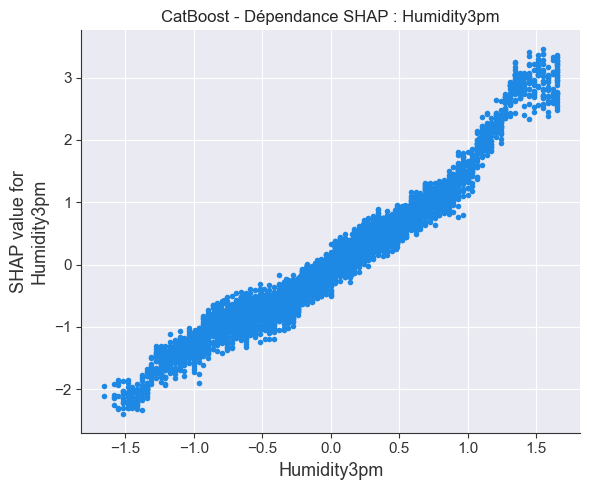

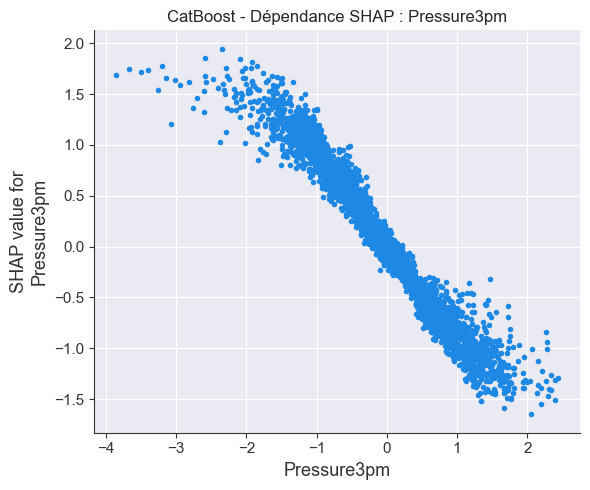

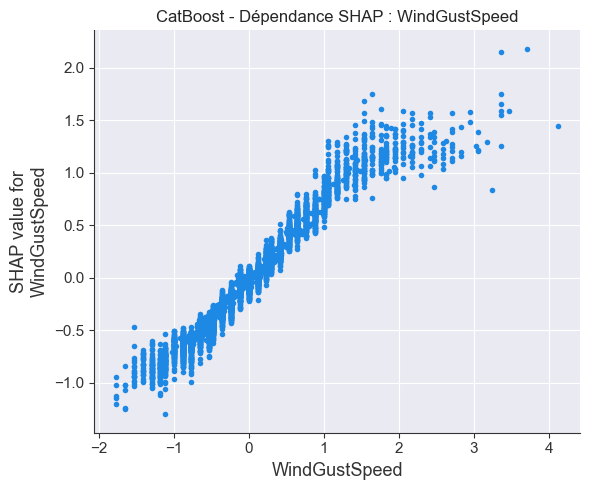

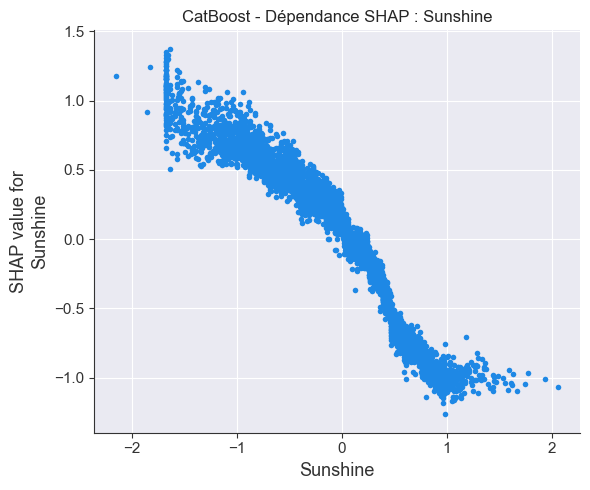

In [32]:
features_dependence = [
    "Humidity3pm",
    "Pressure3pm",
    "WindGustSpeed",
    "Sunshine"
]

for feature in features_dependence:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap,
        interaction_index=None,
        show=False
    )

    plt.title(f"CatBoost - Dépendance SHAP : {feature}")
    plt.tight_layout()
    plt.show()

## 29. Explications SHAP locales

Sélection de prédictions individuelles représentatives.

In [33]:
y_proba_shap = model_cb_opt.predict_proba(X_shap)[:, 1]

local_cases = {
    "Forte probabilité de pluie": np.argmax(y_proba_shap),
    "Faible probabilité de pluie": np.argmin(y_proba_shap),
    "Cas proche du seuil": np.argmin(
        np.abs(y_proba_shap - threshold_opt_final)
    )
}

for name, idx in local_cases.items():
    print(
        f"{name} | "
        f"Probabilité = {y_proba_shap[idx]:.4f} | "
        f"Seuil = {threshold_opt_final:.2f}"
    )

Forte probabilité de pluie | Probabilité = 0.9982 | Seuil = 0.34
Faible probabilité de pluie | Probabilité = 0.0006 | Seuil = 0.34
Cas proche du seuil | Probabilité = 0.3402 | Seuil = 0.34


## 30. Explications locales des prédictions

Les graphiques SHAP suivants décomposent trois prédictions individuelles :
une forte probabilité de pluie, une faible probabilité de pluie et un cas
situé à proximité du seuil de décision.


Forte probabilité de pluie (probabilité pluie = 0.9982)


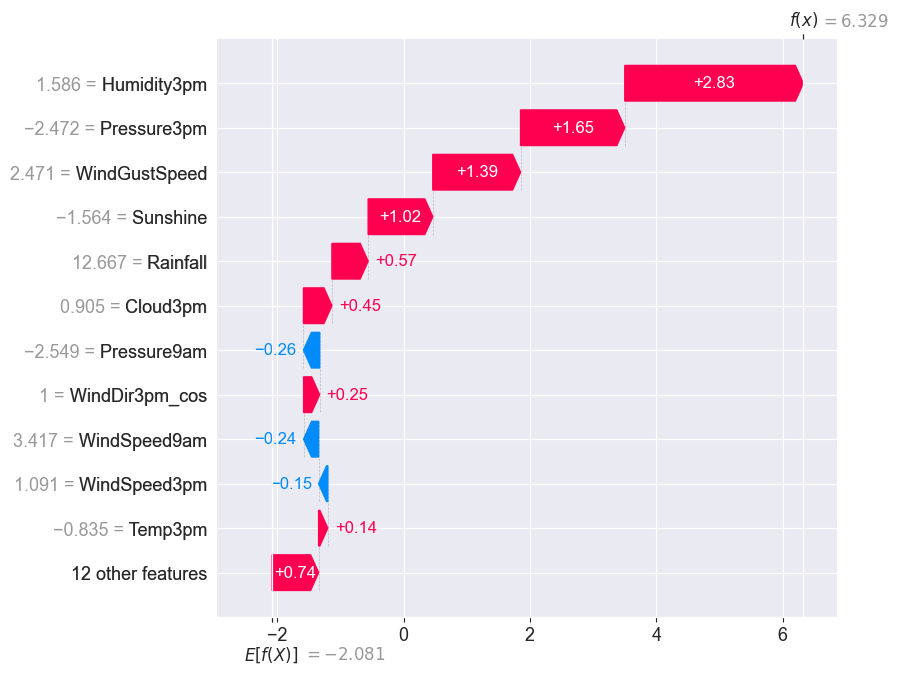


Faible probabilité de pluie (probabilité pluie = 0.0006)


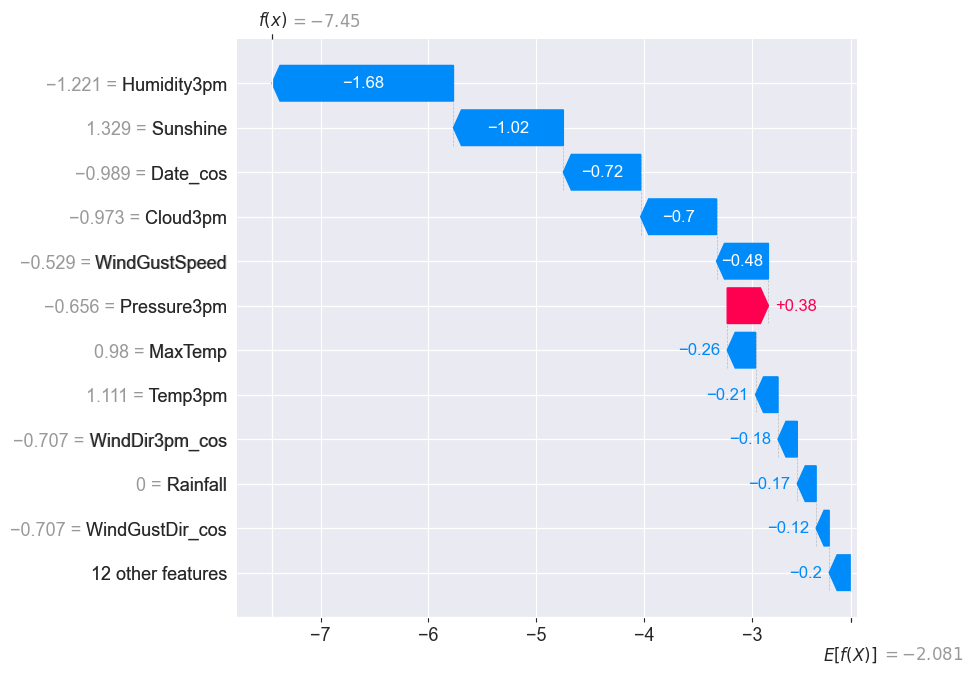


Cas proche du seuil (probabilité pluie = 0.3402)


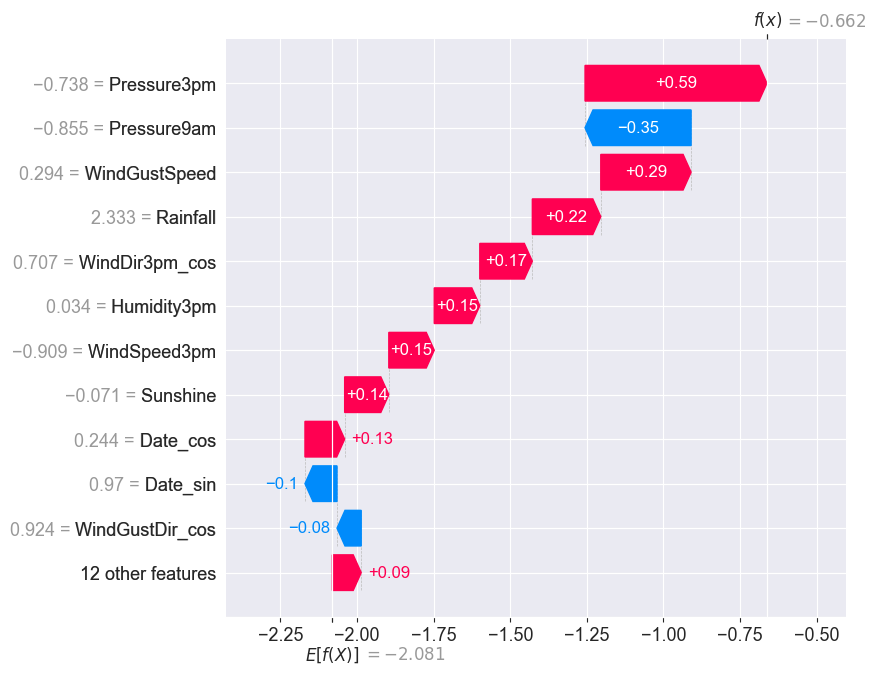

In [34]:

base_value = explainer.expected_value

for name, idx in local_cases.items():

    explanation = shap.Explanation(
        values=shap_values[idx],
        base_values=base_value,
        data=X_shap.iloc[idx].values,
        feature_names=X_shap.columns.tolist()
    )

    print(
        f"\n{name} "
        f"(probabilité pluie = {y_proba_shap[idx]:.4f})"
    )

    shap.plots.waterfall(
        explanation,
        max_display=12,
        show=True
    )

## 31. Analyse locale des erreurs de classification

Afin de compléter l'interprétation du modèle, nous analysons des observations
mal classées au seuil optimisé de 0.34.

L'objectif est d'identifier les variables ayant conduit le modèle à produire
un faux positif ou un faux négatif.

In [35]:
# Prédictions sur l'échantillon utilisé pour SHAP
y_true_shap = y_test.loc[X_shap.index].to_numpy()

y_pred_shap = (
    y_proba_shap >= threshold_opt_final
).astype(int)

# Indices locaux dans X_shap
false_positive_idx = np.where(
    (y_true_shap == 0) & (y_pred_shap == 1)
)[0]

false_negative_idx = np.where(
    (y_true_shap == 1) & (y_pred_shap == 0)
)[0]

print("Faux positifs dans l'échantillon SHAP :", len(false_positive_idx))
print("Faux négatifs dans l'échantillon SHAP :", len(false_negative_idx))

# On choisit les erreurs les plus proches du seuil :
# ce sont les décisions les plus ambiguës.
idx_fp = false_positive_idx[
    np.argmin(
        np.abs(
            y_proba_shap[false_positive_idx]
            - threshold_opt_final
        )
    )
]

idx_fn = false_negative_idx[
    np.argmin(
        np.abs(
            y_proba_shap[false_negative_idx]
            - threshold_opt_final
        )
    )
]

error_cases = {
    "Faux positif proche du seuil": idx_fp,
    "Faux négatif proche du seuil": idx_fn
}

for name, idx in error_cases.items():
    print(
        f"{name} | "
        f"Vraie classe = {y_true_shap[idx]} | "
        f"Probabilité = {y_proba_shap[idx]:.4f} | "
        f"Prédiction = {y_pred_shap[idx]}"
    )

Faux positifs dans l'échantillon SHAP : 449
Faux négatifs dans l'échantillon SHAP : 371
Faux positif proche du seuil | Vraie classe = 0 | Probabilité = 0.3407 | Prédiction = 1
Faux négatif proche du seuil | Vraie classe = 1 | Probabilité = 0.3394 | Prédiction = 0


## 32. Explication SHAP des erreurs proches du seuil

Deux erreurs de classification situées au voisinage du seuil optimal sont
analysées à l'aide de diagrammes SHAP locaux :

- un faux positif : absence de pluie réellement observée, mais pluie prédite ;
- un faux négatif : pluie réellement observée, mais absence de pluie prédite.

Ces observations permettent d'identifier les facteurs responsables des
décisions les plus ambiguës du modèle.


Faux positif proche du seuil | Vraie classe = 0 | Probabilité pluie = 0.3407 | Seuil = 0.34


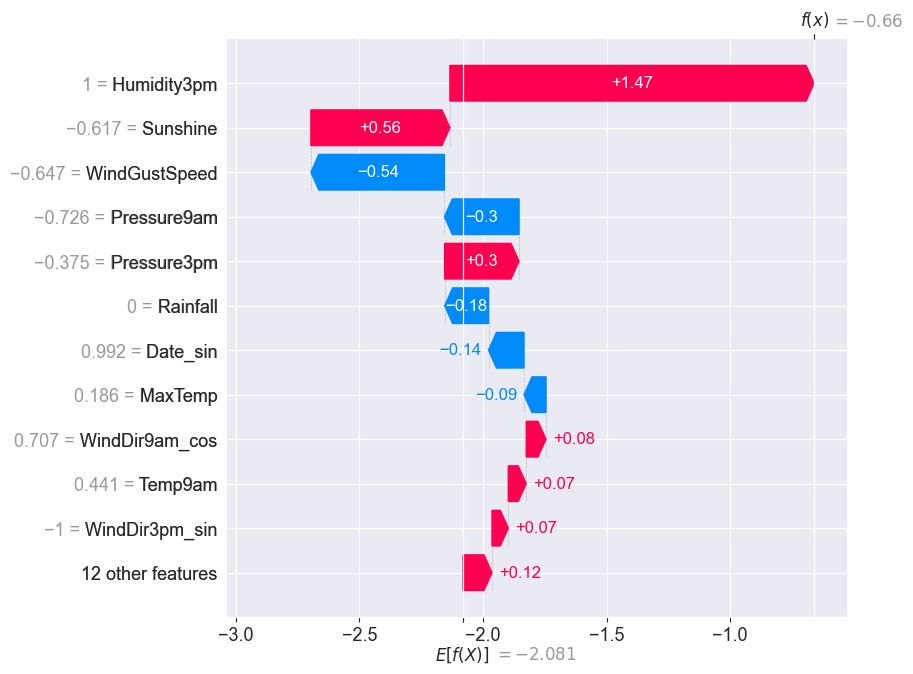


Faux négatif proche du seuil | Vraie classe = 1 | Probabilité pluie = 0.3394 | Seuil = 0.34


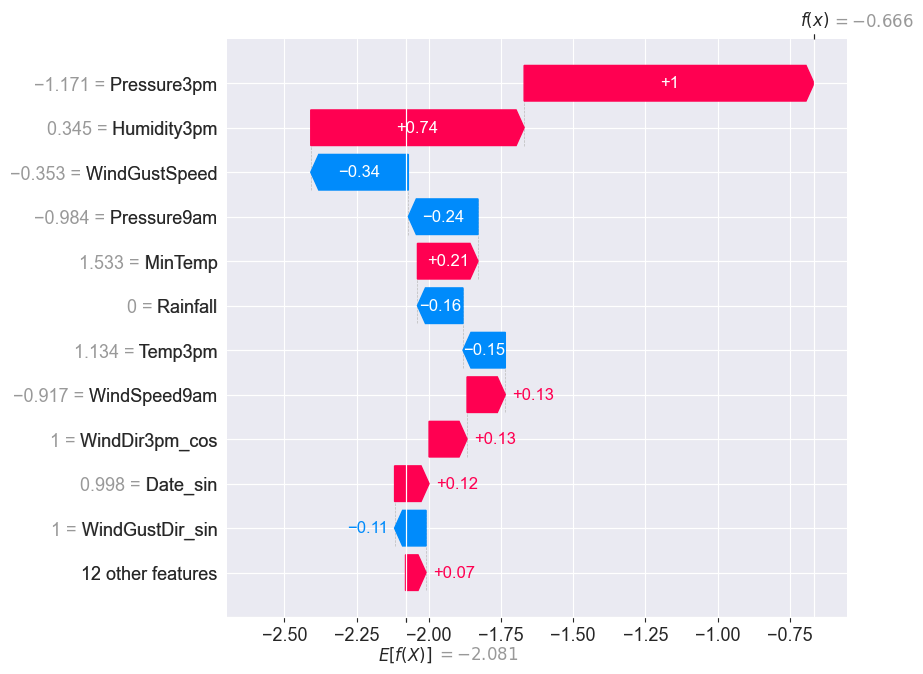

In [36]:
# Explications SHAP des deux erreurs proches du seuil

for name, idx in error_cases.items():

    explanation_error = shap.Explanation(
        values=shap_values[idx],
        base_values=explainer.expected_value,
        data=X_shap.iloc[idx].values,
        feature_names=X_shap.columns
    )

    print(
        f"\n{name} | "
        f"Vraie classe = {y_true_shap[idx]} | "
        f"Probabilité pluie = {y_proba_shap[idx]:.4f} | "
        f"Seuil = {threshold_opt_final:.2f}"
    )

    shap.plots.waterfall(
        explanation_error,
        max_display=12,
        show=True
    )

### Interprétation des erreurs proches du seuil

L'analyse SHAP des erreurs situées au voisinage du seuil de décision met en
évidence le caractère incertain de certaines prédictions.

Pour le faux positif, l'humidité à 15 h constitue le principal facteur
favorisant la prédiction de pluie, tandis que la vitesse des rafales et la
pression à 9 h exercent notamment un effet opposé.

Pour le faux négatif, la pression à 15 h et l'humidité à 15 h augmentent
fortement le score associé à la pluie. Cependant, plusieurs variables,
notamment la vitesse des rafales et la pression à 9 h, compensent ces effets
et placent finalement la probabilité légèrement sous le seuil de décision.

Les deux probabilités obtenues (0.3407 et 0.3394) sont extrêmement proches
du seuil optimisé de 0.34. Ces exemples montrent ainsi que certaines erreurs
proviennent d'observations intrinsèquement ambiguës plutôt que d'une décision
nettement contradictoire du modèle.

Cette analyse complète l'interprétation globale du modèle en montrant comment
les différentes variables interagissent pour produire une prédiction
individuelle.

## 33. Comparaison des méthodes d'importance des variables

Trois approches complémentaires ont été utilisées pour interpréter le modèle :

- l'importance native de CatBoost ;
- l'importance par permutation ;
- l'importance globale issue des valeurs SHAP.

Les échelles de ces méthodes étant différentes, leur comparaison est réalisée
à partir du rang attribué à chaque variable. Une variable obtenant un rang
faible de manière répétée peut ainsi être considérée comme importante de façon
robuste, indépendamment de la méthode d'interprétation utilisée.

In [37]:
# ============================================================
# Comparaison des importances : CatBoost / permutation / SHAP
# ============================================================

# 1. Importance native CatBoost
importance_native_compare = pd.DataFrame({
    "Variable": X_test.columns,
    "CatBoost": model_cb_opt.get_feature_importance()
})

# 2. Importance par permutation
importance_perm_compare = permutation_df[
    ["Variable", "Importance"]
].copy()

importance_perm_compare = importance_perm_compare.rename(
    columns={"Importance": "Permutation"}
)

# 3. Importance globale SHAP
# moyenne de la valeur absolue des contributions SHAP
importance_shap_compare = pd.DataFrame({
    "Variable": X_shap.columns,
    "SHAP": np.abs(np.asarray(shap_values)).mean(axis=0)
})

# Fusion des trois méthodes
importance_compare = (
    importance_native_compare
    .merge(importance_perm_compare, on="Variable", how="inner")
    .merge(importance_shap_compare, on="Variable", how="inner")
)

# ------------------------------------------------------------
# Conversion en rangs
# rang 1 = variable la plus importante
# ------------------------------------------------------------

importance_compare["Rang_CatBoost"] = (
    importance_compare["CatBoost"]
    .rank(ascending=False, method="min")
)

importance_compare["Rang_Permutation"] = (
    importance_compare["Permutation"]
    .rank(ascending=False, method="min")
)

importance_compare["Rang_SHAP"] = (
    importance_compare["SHAP"]
    .rank(ascending=False, method="min")
)

# Rang moyen sur les trois méthodes
importance_compare["Rang_moyen"] = importance_compare[
    ["Rang_CatBoost", "Rang_Permutation", "Rang_SHAP"]
].mean(axis=1)

importance_compare = importance_compare.sort_values(
    "Rang_moyen"
).reset_index(drop=True)

# Affichage
print(
    importance_compare[
        [
            "Variable",
            "Rang_CatBoost",
            "Rang_Permutation",
            "Rang_SHAP",
            "Rang_moyen"
        ]
    ]
    .head(15)
    .round(2)
    .to_string(index=False)
)

       Variable  Rang_CatBoost  Rang_Permutation  Rang_SHAP  Rang_moyen
    Humidity3pm            1.0               1.0        1.0        1.00
    Pressure3pm            2.0               2.0        2.0        2.00
       Sunshine            3.0               4.0        3.0        3.33
  WindGustSpeed            4.0               3.0        4.0        3.67
    Pressure9am            7.0               5.0        7.0        6.33
       Cloud3pm            6.0               8.0        6.0        6.67
       Date_cos            5.0               6.0        9.0        6.67
       Rainfall            8.0               9.0        5.0        7.33
 WindDir3pm_cos           10.0               7.0        8.0        8.33
   WindSpeed3pm           13.0              10.0       12.0       11.67
WindGustDir_sin           11.0              12.0       15.0       12.67
        Temp9am           14.0              11.0       14.0       13.00
        MaxTemp           12.0              13.0       17.0     

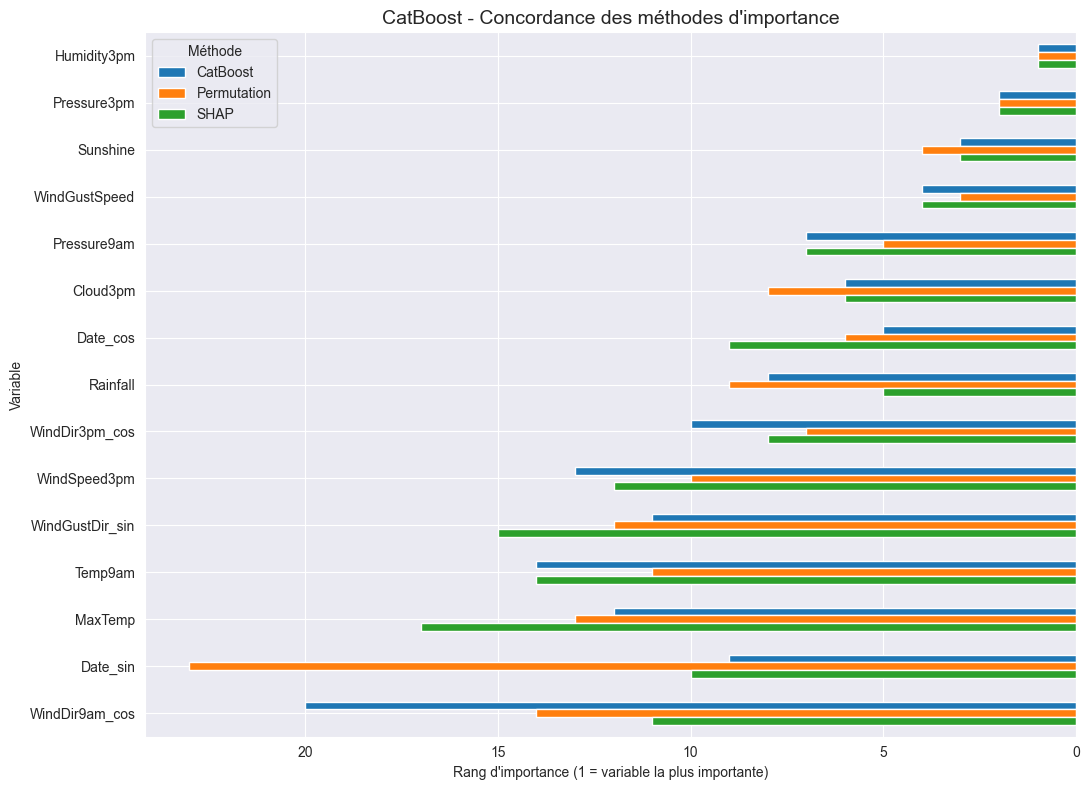

In [38]:
# ============================================================
# Visualisation de la concordance des trois méthodes
# ============================================================

top_n = 15

rank_plot = (
    importance_compare
    .head(top_n)
    .set_index("Variable")[
        ["Rang_CatBoost", "Rang_Permutation", "Rang_SHAP"]
    ]
)

ax = rank_plot.plot(
    kind="barh",
    figsize=(11, 8)
)

ax.invert_yaxis()
ax.invert_xaxis()

plt.title(
    "CatBoost - Concordance des méthodes d'importance",
    fontsize=14
)
plt.xlabel("Rang d'importance (1 = variable la plus importante)")
plt.ylabel("Variable")
plt.legend(
    ["CatBoost", "Permutation", "SHAP"],
    title="Méthode"
)
plt.tight_layout()
plt.show()

### Concordance des méthodes d'interprétation

La comparaison des rangs obtenus avec l'importance native de CatBoost,
l'importance par permutation et les valeurs SHAP met en évidence une forte
concordance pour les principales variables du modèle.

`Humidity3pm` et `Pressure3pm` occupent respectivement les première et deuxième
positions quelle que soit la méthode utilisée. `Sunshine` et `WindGustSpeed`
complètent également de manière stable le groupe des variables les plus
influentes.

Certaines différences apparaissent pour les variables d'importance intermédiaire.
Par exemple, `Rainfall` présente une importance plus élevée selon SHAP que selon
l'importance native ou la permutation. À l'inverse, certaines variables
temporelles telles que `Date_sin` peuvent être utilisées par le modèle sans que
leur permutation entraîne une diminution importante des performances.

Cette convergence entre plusieurs méthodes complémentaires renforce ainsi la
robustesse de l'interprétation globale du modèle : l'humidité en fin de journée,
la pression atmosphérique, l'ensoleillement et la vitesse des rafales constituent
les principaux déterminants de la prédiction de pluie du lendemain.

## Interprétabilité de la décision autour du seuil

L'optimisation du seuil de classification a conduit à retenir un seuil de 0,34
pour la prédiction de pluie. Les observations dont la probabilité prédite est
proche de cette valeur sont particulièrement intéressantes : de faibles
variations dans les contributions des variables peuvent modifier la décision
finale du modèle.

L'analyse SHAP suivante vise donc à caractériser les facteurs qui poussent les
prédictions proches de la frontière de décision vers la classe « pluie » ou
vers la classe « pas de pluie ».

In [39]:
# ============================================================
# Analyse SHAP des observations proches du seuil de décision
# ============================================================

y_proba_shap = model_cb_opt.predict_proba(X_shap)[:, 1]

margin = 0.05

near_threshold_mask = (
    np.abs(y_proba_shap - threshold_opt_final) <= margin
)

X_near = X_shap.loc[near_threshold_mask].copy()

shap_near = np.asarray(shap_values)[near_threshold_mask]

proba_near = y_proba_shap[near_threshold_mask]

print(
    f"Seuil de décision : {threshold_opt_final:.2f}"
)
print(
    f"Zone étudiée : "
    f"[{threshold_opt_final - margin:.2f}, "
    f"{threshold_opt_final + margin:.2f}]"
)
print(
    f"Nombre d'observations proches du seuil : "
    f"{len(X_near)}"
)

near_importance = pd.DataFrame({
    "Variable": X_near.columns,
    "Importance_SHAP_proche_seuil":
        np.abs(shap_near).mean(axis=0)
})

near_importance = (
    near_importance
    .sort_values(
        "Importance_SHAP_proche_seuil",
        ascending=False
    )
    .reset_index(drop=True)
)

print()
print(
    near_importance
    .head(15)
    .round(4)
    .to_string(index=False)
)

Seuil de décision : 0.34
Zone étudiée : [0.29, 0.39]
Nombre d'observations proches du seuil : 299

      Variable  Importance_SHAP_proche_seuil
   Humidity3pm                        0.6803
   Pressure3pm                        0.5060
 WindGustSpeed                        0.4444
      Sunshine                        0.4318
      Rainfall                        0.2634
      Cloud3pm                        0.2225
   Pressure9am                        0.1735
WindDir3pm_cos                        0.1232
      Date_cos                        0.0998
WindDir9am_cos                        0.0846
      Date_sin                        0.0831
  WindSpeed3pm                        0.0763
  WindSpeed9am                        0.0692
       Temp9am                        0.0583
WindDir9am_sin                        0.0524


## 36. Sens des contributions SHAP

In [40]:
above_mask = proba_near >= threshold_opt_final
below_mask = proba_near < threshold_opt_final

shap_above = shap_near[above_mask]
shap_below = shap_near[below_mask]

direction_df = pd.DataFrame({
    "Variable": X_near.columns,
    "SHAP_moyen_prediction_pluie": shap_above.mean(axis=0),
    "SHAP_moyen_prediction_pas_pluie": shap_below.mean(axis=0)
})

direction_df = direction_df.merge(
    near_importance,
    on="Variable"
)

direction_df = direction_df.sort_values(
    "Importance_SHAP_proche_seuil",
    ascending=False
).reset_index(drop=True)

print(f"Observations classées pluie : {above_mask.sum()}")
print(f"Observations classées pas de pluie : {below_mask.sum()}")

print()

print(
    direction_df[
        [
            "Variable",
            "SHAP_moyen_prediction_pluie",
            "SHAP_moyen_prediction_pas_pluie"
        ]
    ]
    .head(10)
    .round(4)
    .to_string(index=False)
)

Observations classées pluie : 130
Observations classées pas de pluie : 169

      Variable  SHAP_moyen_prediction_pluie  SHAP_moyen_prediction_pas_pluie
   Humidity3pm                       0.4265                           0.4199
   Pressure3pm                       0.2820                           0.1783
 WindGustSpeed                       0.1102                           0.0043
      Sunshine                       0.3857                           0.3708
      Rainfall                       0.1216                           0.0632
      Cloud3pm                       0.1847                           0.1897
   Pressure9am                      -0.0924                          -0.0448
WindDir3pm_cos                       0.0467                           0.0400
      Date_cos                       0.0396                           0.0408
WindDir9am_cos                       0.0223                           0.0207


## 37. Contributions près du seuil

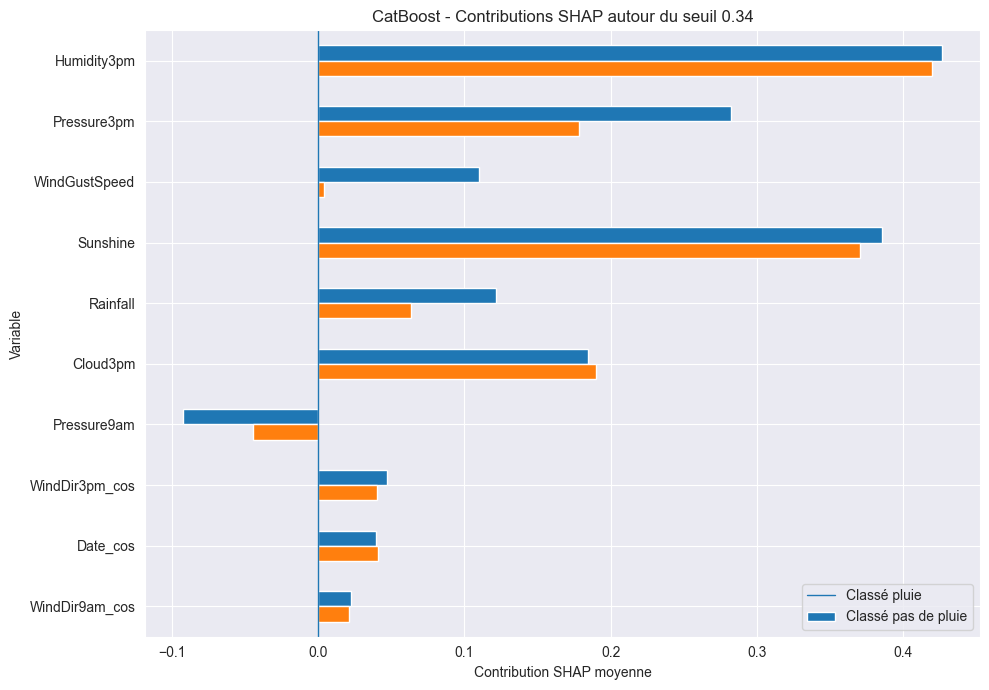

In [41]:
top_direction = direction_df.head(10).copy()

plot_df = top_direction.set_index("Variable")[
    [
        "SHAP_moyen_prediction_pluie",
        "SHAP_moyen_prediction_pas_pluie"
    ]
]

ax = plot_df.plot(
    kind="barh",
    figsize=(10, 7)
)

ax.invert_yaxis()

plt.axvline(0, linewidth=1)
plt.title("CatBoost - Contributions SHAP autour du seuil 0.34")
plt.xlabel("Contribution SHAP moyenne")
plt.ylabel("Variable")
plt.legend(["Classé pluie", "Classé pas de pluie"])
plt.tight_layout()
plt.show()

### Interprétation autour du seuil

Autour du seuil de décision de 0.34, les prédictions reposent principalement sur **Humidity3pm, Sunshine, Pressure3pm et WindGustSpeed**.

Humidity3pm et Sunshine restent fortement contributives quelle que soit la classe finalement prédite, ce qui confirme leur rôle central dans les situations incertaines.

En revanche, **Pressure3pm, WindGustSpeed et Rainfall** contribuent davantage aux observations classées pluie. Ces variables semblent donc jouer un rôle important pour départager les observations lorsque la probabilité prédite est proche du seuil.

Cette analyse confirme que les décisions proches de 0.34 ne reposent pas sur une seule variable, mais sur la combinaison de plusieurs conditions météorologiques.

# Conclusion

Le modèle **CatBoost** fournit de bonnes performances pour la prédiction de la pluie, avec un **ROC-AUC de 0.8811** et un **PR-AUC de 0.7249** sur le jeu de test.

L'optimisation du seuil de décision conduit à retenir un seuil de **0.34** plutôt que le seuil standard de 0.50. Ce choix améliore la détection des jours de pluie : le **recall passe de 0.5467 à 0.6841** et le **F1-score de la classe pluie de 0.6258 à 0.6585**, au prix d'une diminution de la précision de 0.7315 à 0.6348. Ce compromis est cohérent avec l'objectif de limiter les jours de pluie non détectés.

Une pondération spécifique de la classe pluie a également été étudiée. Elle permet d'augmenter légèrement le recall jusqu'à **0.6978**, mais sans améliorer suffisamment les autres métriques pour justifier sa sélection. Le modèle non pondéré avec un seuil de **0.34** est donc retenu.

Les différentes méthodes d'interprétabilité sont globalement concordantes. **Humidity3pm** et **Pressure3pm** apparaissent systématiquement comme les variables les plus importantes, suivies principalement par **Sunshine** et **WindGustSpeed**. L'analyse SHAP permet également d'identifier le sens de leurs effets : une humidité élevée et des rafales importantes favorisent la prédiction de pluie, tandis qu'une pression atmosphérique ou un ensoleillement élevés tendent à la réduire.

Enfin, l'analyse locale et l'étude des observations proches du seuil montrent que les décisions les plus incertaines reposent sur la combinaison de plusieurs conditions météorologiques, notamment **Humidity3pm, Pressure3pm, WindGustSpeed, Sunshine et Rainfall**.

Le modèle final retenu est donc **CatBoost non pondéré avec un seuil de décision de 0.34**, offrant un compromis satisfaisant entre capacité de discrimination, détection des jours de pluie et interprétabilité.

## 38. Export du CatBoost baseline

In [42]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

artifact_cb_base = {
    "model": model_cb_base,
    "threshold": 0.50,
    "features": X_train.columns.tolist(),
    "version": "baseline"
}

joblib.dump(
    artifact_cb_base,
    models_dir / "catboost_baseline.joblib"
)

print("Modèle enregistré :", models_dir / "catboost_baseline.joblib")

Modèle enregistré : ..\models\catboost_baseline.joblib


## 39. Export du CatBoost final

In [43]:
artifact_cb_final = {
    "model": model_cb_opt,
    "threshold": threshold_opt_final,
    "features": X_train.columns.tolist(),
    "version": "optimized"
}

joblib.dump(
    artifact_cb_final,
    models_dir / "catboost_final.joblib"
)

print("Modèle enregistré :", models_dir / "catboost_final.joblib")
print("Seuil enregistré :", threshold_opt_final)

Modèle enregistré : ..\models\catboost_final.joblib
Seuil enregistré : 0.33999999999999986


## 40. Export du CatBoost pondéré

In [44]:
artifact_cb_weighted = {
    "model": model_cb_weighted,
    "threshold": threshold_weighted_opt,
    "features": X_train.columns.tolist(),
    "version": "weighted"
}

joblib.dump(
    artifact_cb_weighted,
    models_dir / "catboost_weighted.joblib"
)

print("Modèle enregistré :", models_dir / "catboost_weighted.joblib")
print("Seuil enregistré :", threshold_weighted_opt)

Modèle enregistré : ..\models\catboost_weighted.joblib
Seuil enregistré : 0.6099999999999998
